# Explainable Crosstalk Diagnosis on Arango

A signal-integrity agent on the Arango Contextual Data Platform. It answers one question no
single design-rule check can: **which physical adjacency on a board explains a frequency
variation on a data lane, and how was that fault fixed before.**

This notebook runs the whole pipeline against the real code in `src/`. Nothing here duplicates
the scripts; each cell calls into `parse_board.py`, `ingest.py`, `agent.py`, and
`agent_graph.py`, so the notebook and the repo never drift.

The pipeline builds three data shapes on one deployment:

- **A design graph** parsed from a real KiCad board: nets as nodes, close parallel runs as
  adjacency edges carrying spacing, length, layer, and trace width.
- **Vector recall** over a corpus of past defect reports, embedded for similarity search.
- **A knowledge graph** built by AutoGraph from the same corpus, queried through the
  Retriever, that cites the fix behind a fault.

The agent then embeds the symptom, recalls similar past defects, traverses the design graph,
**scores each candidate adjacency**, **judges which one explains the symptom**, and returns a
**cited fix** through the Retriever (Instant Search, or Deep Search for a full reasoned playbook).

**Hero fault — clock-into-data crosstalk:** a DSI clock lane running 43 mm alongside a data
lane from a different camera interface, 0.42 mm apart on the bottom copper layer. The victim is
not hardcoded; auto mode scans the board and finds the worst adjacency, which turns out to be
`DSI1_D0_N`.

**Before you start:** copy `.env.example` to `.env` and fill in your Arango, OpenAI, and
Retriever credentials. Run this notebook from the repo root.

## Dependencies

The notebook talks to Arango and OpenAI, draws the severity map with matplotlib + networkx, and
uses LangGraph for the optional framework variant. Install everything once with the cell below.
Already-installed packages are skipped.

In [ ]:
# --- Dependencies: run once ---
%pip install -q python-arango openai python-dotenv pandas matplotlib networkx
# Optional (only for the LangGraph framework variant in section 8):
%pip install -q langchain langchain-openai langgraph
print("dependencies installed. If this was a first-time install, restart the kernel, then continue.")

## Setup

Everything downstream reads from `config.py`. Change the board, the 3W spacing rule, or the
severity weights there and the whole pipeline follows. This cell connects to the deployment
and confirms the server is reachable before any data lands.

In [1]:
import sys
sys.path.insert(0, ".")      # config.py may live at the repo root
sys.path.insert(0, "src")    # parse_board / ingest / agent / agent_graph live in src/

import os
from arango import ArangoClient
from openai import OpenAI
from dotenv import load_dotenv

import config as C

load_dotenv()
oai = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))

client = ArangoClient(hosts=os.environ["ARANGO_HOST"])
db = client.db(
    os.environ["ARANGO_DB"],
    username=os.environ["ARANGO_USER"],
    password=os.environ["ARANGO_PASSWORD"],
)
print("connected to:", db.name, "| server:", db.version())

connected to: crosstalk | server: 3.12.11


## 1. The schema — one store, three shapes

A board defect is not a value in one table; it is a relationship between two nets. This step
lays out the shape that relationship lives in: a document collection for the nets (nodes), an
edge collection for the adjacencies between them, a document collection for the defect reports,
and one named graph over the edges. The agent's traversal walks this graph.

`setup_collections` is idempotent, so it is safe to re-run.

In [2]:
import ingest

ingest.setup_collections(db)

print("collections:")
for c in sorted(col["name"] for col in db.collections() if not col["name"].startswith("_")):
    print("  ", c)

collections:
   adjacencies
   defect_reports
   nets


## 2. The board — nets and adjacencies

`load_board` parses the real KiCad `.kicad_pcb` file and writes the design graph. It reads every
copper trace, groups the segments by net, and computes which nets run close and parallel enough
to couple. Intended closeness is skipped: differential pairs, and the lanes of one interface
routed together as a bus. What remains are the accidental cross-interface adjacencies where
crosstalk actually lives.

In [3]:
stats = ingest.load_board(db, "data/CM4IOUSB3.kicad_pcb")
print("board loaded:", stats)

# class breakdown of the nets in scope
rows = list(db.aql.execute("""
  FOR n IN nets
    COLLECT cls = n.net_class WITH COUNT INTO n_count
    SORT n_count DESC
    RETURN {class: cls, count: n_count}
"""))
for r in rows:
    print(f"  {r['class']:<8} {r['count']}")

board loaded: {'nets': 73, 'adjacencies': 10}
  data     56
  clock    12
  power    5


## 3. Write the defect corpus

No public dataset ties past crosstalk incidents to trace geometry, so the corpus is written for
this build. `prepare_autograph.py` generates 30 markdown reports (6 close matches to the hero
mechanism, 12 near-misses with the same symptom but a different cause, 12 filler cases), plus a
manifest. The seeding labels live only in the manifest, never in the reports, so nothing about
how the corpus was built leaks into the knowledge graph AutoGraph will extract.

In [4]:
import prepare_autograph as prep

counts = prep.generate_corpus("data/autograph")
print("corpus written to data/autograph/:", counts)

corpus written to data/autograph/: {'close_match': 6, 'near_miss': 12, 'filler': 12}


## 4. Embed the corpus and build the vector index

The geometry answers *where* the nets run. The defect corpus answers *whether this pattern has
failed before*. `load_defects` embeds each report with the same model the query uses, and
`build_vector_index` builds the index that powers `APPROX_NEAR_COSINE`. The corpus is synthetic
and labeled as such; each case models a documented signal-integrity mechanism.

The corpus files are written by `prepare_autograph.py` (next-to-last step). If `data/autograph/`
is empty, run that cell first.

In [5]:
defect_stats = ingest.load_defects(db, oai, "data/autograph")
index_stats = ingest.build_vector_index(db, dimension=defect_stats.get("dimension"))
print("defects:", defect_stats)
print("index :", index_stats)

defects: {'defect_reports': 30, 'dimension': 1536}
index : {'dimension': 1536}


## 5. Verify the fault exists

Before running the agent, confirm the graph actually contains the hero adjacency, and that a
clean lane does not. The same traversal the agent uses, run by hand: from the victim net out to
its neighbors, reading each edge's geometry. The hero (`DSI1_D0_N`) should show a tight, long
clock adjacency; a healthy USB3 lane (`SSTX1_N`) should show only a weak, short one.

In [6]:
def neighbours(victim_key):
    return list(db.aql.execute("""
      FOR neighbour, edge IN 1..1 OUTBOUND @victim GRAPH @graph
        SORT edge.spacing_mm ASC
        RETURN {
          aggressor: neighbour.name, class: neighbour.net_class,
          spacing_mm: edge.spacing_mm, parallel_len_mm: edge.parallel_len_mm, layer: edge.layer
        }
    """, bind_vars={"victim": f"nets/{victim_key}", "graph": C.GRAPH_NAME}))

def victim_key(name_like):
    r = list(db.aql.execute(
        "FOR n IN nets FILTER n.name LIKE @p RETURN n._key",
        bind_vars={"p": f"%{name_like}%"}))
    return r[0] if r else None

hero = victim_key("DSI1_D0_N")
clean = victim_key("SSTX1_N")
print(f"HERO  {hero} (DSI1_D0_N):")
for c in neighbours(hero):
    print(f"    {c['aggressor']:<28} [{c['class']:<5}] gap {c['spacing_mm']}mm  len {c['parallel_len_mm']}mm  {c['layer']}")
print(f"\nCLEAN {clean} (SSTX1_N):")
for c in neighbours(clean):
    print(f"    {c['aggressor']:<28} [{c['class']:<5}] gap {c['spacing_mm']}mm  len {c['parallel_len_mm']}mm  {c['layer']}")

HERO  net_47 (DSI1_D0_N):
    /CM4_HighSpeed/DSI0_C_P      [clock] gap 0.42mm  len 43.3mm  B.Cu
    /CM4_HighSpeed/DSI0_C_N      [clock] gap 0.8mm  len 43.3mm  B.Cu

CLEAN net_106 (SSTX1_N):
    /xHCI-USB3/SSRX1_P           [data ] gap 0.8037mm  len 2.04mm  F.Cu


## 6. Build the knowledge graph with AutoGraph (web interface)

The geometry finds that a clock runs close to a data lane. It cannot say how that fault was
fixed before. AutoGraph turns the corpus into a knowledge graph the Retriever can cite. This
step is done in the Arango web interface, not scripted here:

1. Open **AutoGraph Studio** and create a project, e.g. `crosstalk-defect-corpus`.
2. Upload the 30 markdown files from `data/autograph/` under one category (`past-defects`).
3. Set the embedding model to `text-embedding-3-small`, matching `config.EMBEDDING_MODEL`.
4. Build the graph. AutoGraph produces a **Corpus Graph** and a **Knowledge Graph**
   (on this corpus, roughly 480 entities and 1,000 relationships).
5. Deploy the **Retriever**, then set `RETRIEVER_ID` and `RETRIEVER_BASE` in `.env`.

Until the Retriever is configured, the agent falls back to a local corpus citation, so the rest
of the notebook runs either way.

## 7. The marquee query — one round trip

The agent's core is a single AQL query. In one round trip it runs the graph traversal out from
the victim net and the vector recall over past defects, and returns both together:

- the **graph traversal** to the physically adjacent nets, with their spacing, length, and layer,
- **vector recall** of similar past defect reports (`APPROX_NEAR_COSINE`, in its own subquery so
  it keeps the top-level sort the vector index requires).

The reasoning and the citation add calls around this query. It is worth reading in full.

In [7]:
import agent
print(agent.MARQUEE)


LET similar = (
    FOR d IN defect_reports
        SORT APPROX_NEAR_COSINE(d.embedding, @symptom_vec) DESC
        LIMIT @k
        RETURN { id: d._key, title: d.title, text: d.text }
)
LET candidates = (
    FOR neighbour, edge IN 1..1 OUTBOUND @victim GRAPH @graph
        RETURN {
            aggressor_key: neighbour._key,
            aggressor_name: neighbour.name,
            aggressor_class: neighbour.net_class,
            aggressor_activity: neighbour.activity,
            spacing_mm: edge.spacing_mm,
            parallel_len_mm: edge.parallel_len_mm,
            layer: edge.layer,
            trace_width_mm: edge.trace_width_mm
        }
)
RETURN { similar: similar, candidates: candidates }



## 8. Run the agent on the hero — fast path

`resolve()` runs the whole investigation: recall, traverse, score each candidate, judge which
one explains the symptom, cite the fix, and corroborate. `auto` is not used here; the hero net
is passed directly. The judge's pick is a hypothesis, and the finding's tier is capped at
`corroborated` until hardware confirms it.

In [8]:
symptom = "frequency variation and rising bit error rate on a high-speed data lane"
result = agent.resolve(db, oai, hero, symptom)
agent._print_result(result)

  [marquee: one AQL round trip]

=== VICTIM ===
/CM4_HighSpeed/DSI1_D0_N (net_47)  symptom: frequency variation and rising bit error rate on a high-speed data lane

=== CANDIDATES (ranked, proved) ===
  /CM4_HighSpeed/DSI0_C_P              sev 0.5873 [leading]  clock   gap 0.42mm  len 43.3mm  B.Cu
  /CM4_HighSpeed/DSI0_C_N              sev 0.4487 [unlikely]  clock   gap 0.8mm  len 43.3mm  B.Cu

=== RECALLED CASES ===
  Frequency variation traced to an impedance mismatch
  Camera lane jitter from an adjacent high-speed signal
  Bit errors from power-supply ripple on a driver rail
  Bit errors cleared by shortening a coupled bus segment
  Rising bit error rate from a ground-plane void

=== JUDGE (interpretation, a hypothesis) ===
  chosen: net_37
  judge confidence: medium  ->  finding tier [corroborated]
  reasoning: Hypothesis: far‑end crosstalk from /CM4_HighSpeed/DSI0_C_P (net_37) is the most likely adjacency cause of the observed frequency variation and rising BER on /CM4_HighSpeed/

## 8b. (Optional, slow) Deep Search — the full reasoned playbook

Setting `deep=True` calls the Retriever's Deep Search: a multi-step investigation that returns
an ordered remediation with fuller citations. Slower and higher cost; requires the Retriever to
be deployed and configured in `.env`.

In [9]:
# WARNING: slow (minutes) and higher cost. Requires RETRIEVER_ID / RETRIEVER_BASE set.
deep_result = agent.resolve(db, oai, hero, symptom, deep=True)
print(deep_result["cited_fix"]["answer"])

  [marquee: one AQL round trip]
Summary — likely root cause and what fixed it in past, short answer
- The most likely root cause for frequency variation and a rising BER on /CM4_HighSpeed/DSI1_D0_N when it runs 43.3 mm parallel at 0.42 mm spacing to /CM4_HighSpeed/DSI0_C_P on B.Cu is far‑end/near‑end crosstalk (aggressor clock or continuously switching lane coupling into the data lane) enabled by a long, relatively tight parallel run. [1][2][3][4][5]  
- Past defect reports show this was frequently compounded by return‑path (reference‑plane) discontinuities or connector/transition impedance discontinuities that converted coupling/energy into timing/frequency variation and elevated BER. [6][7]  

Field‑proven fixes used in similar cases (ordered from least to most invasive)
1. Local pull‑apart (increase spacing across the coupled span) — restored link margin in multiple reports when space permitted. [2][3]  
2. Add a grounded guard/shield trace between aggressor and victim and stitch it

## 9. The framework variant — a LangGraph ReAct agent

`agent.py` decides the step order itself: traverse, score, judge, cite. This variant hands the
control loop to a framework instead. It exposes three tools and lets an LLM choose which to call
and when to stop. Same tools, same database, same answer; only the orchestration differs.

In [10]:
# The framework variant: same three tools, but an LLM chooses the order.
# Self-contained import so the rest of the notebook does not depend on LangChain.
import agent_graph
agent_graph.run(db, oai, hero)

  [agent picks tool] traverse_and_score
  [agent picks tool] recall_similar
  [agent picks tool] cite_fix

=== FINAL ASSESSMENT (framework agent) ===
1) traverse_and_score (physical candidates)
- Results for victim net_47:
  - net_37 — /CM4_HighSpeed/DSI0_C_P (clock)
    - layer: B.Cu
    - spacing: 0.42 mm
    - parallel length: 43.3 mm
    - severity: 0.5873 (leading)
  - net_36 — /CM4_HighSpeed/DSI0_C_N (clock)
    - layer: B.Cu
    - spacing: 0.80 mm
    - parallel length: 43.3 mm
    - severity: 0.4487 (unlikely)

2) recall_similar (past cases matching symptom + geometry)
- Returned examples (summaries): long (~44–52 mm) same-layer adjacency between a clock and a victim producing far-end crosstalk/jitter/BER. Fixes that worked in those cases: widen spacing where possible; add grounded guard (shield) with stitching vias; or move the aggressor to another (inner) layer to restore a solid reference plane and break the long parallel run.

3) Chosen adjacency (single hypothesis)
- I cho

'1) traverse_and_score (physical candidates)\n- Results for victim net_47:\n  - net_37 — /CM4_HighSpeed/DSI0_C_P (clock)\n    - layer: B.Cu\n    - spacing: 0.42 mm\n    - parallel length: 43.3 mm\n    - severity: 0.5873 (leading)\n  - net_36 — /CM4_HighSpeed/DSI0_C_N (clock)\n    - layer: B.Cu\n    - spacing: 0.80 mm\n    - parallel length: 43.3 mm\n    - severity: 0.4487 (unlikely)\n\n2) recall_similar (past cases matching symptom + geometry)\n- Returned examples (summaries): long (~44–52 mm) same-layer adjacency between a clock and a victim producing far-end crosstalk/jitter/BER. Fixes that worked in those cases: widen spacing where possible; add grounded guard (shield) with stitching vias; or move the aggressor to another (inner) layer to restore a solid reference plane and break the long parallel run.\n\n3) Chosen adjacency (single hypothesis)\n- I choose net_37 (/CM4_HighSpeed/DSI0_C_P) as the likely aggressor.\n  - Reasoning: it is the closest (0.42 mm) and runs long (43.3 mm) on

## 10. The whole board — every fault ranked

One adjacency is a finding; the board is the point. `worst_victim` scans every edge and scores
it, so the hero is ranked against the full field of ten real adjacencies rather than seen alone.

In [11]:
import pandas as pd

edges = list(db.aql.execute(agent.ALL_EDGES_Q))
for e in edges:
    e["severity"], _ = agent.severity(e)
edges.sort(key=lambda e: e["severity"], reverse=True)

df = pd.DataFrame([{
    "victim": e["victim_key"], "aggressor": e["aggressor_name"].split("/")[-1],
    "class": e["aggressor_class"], "severity": e["severity"],
    "spacing_mm": e["spacing_mm"], "parallel_len_mm": e["parallel_len_mm"], "layer": e["layer"],
} for e in edges])
df.head(12)

,victim,aggressor,class,severity,spacing_mm,parallel_len_mm,layer
0,net_47,DSI0_C_P,clock,0.5873,0.420,43.3,B.Cu
1,net_22,DSI0_D0_N,data,0.5363,0.420,48.1,B.Cu
2,net_32,CAM1_D3_P,data,0.5363,0.420,48.1,B.Cu
3,net_156,nOCS1,data,0.5337,0.277,8.5,B.Cu
4,net_159,nPWR,data,0.5337,0.277,8.5,B.Cu
5,net_37,DSI1_D0_N,data,0.5043,0.420,43.3,B.Cu
6,net_47,DSI0_C_N,clock,0.4487,0.800,43.3,B.Cu
7,net_46,DSI0_C_P,clock,0.4487,0.800,43.3,B.Cu
8,net_22,DSI0_D0_P,data,0.3977,0.800,48.1,B.Cu
9,net_33,CAM1_D3_P,data,0.3977,0.800,48.1,B.Cu


## 11. The board severity map

Color the fault field by severity. Each node is a net, each edge a real adjacency; the edge
width and color track the severity score, so the hero clock-to-data coupling stands out from the
healthy neighbors before any query runs.

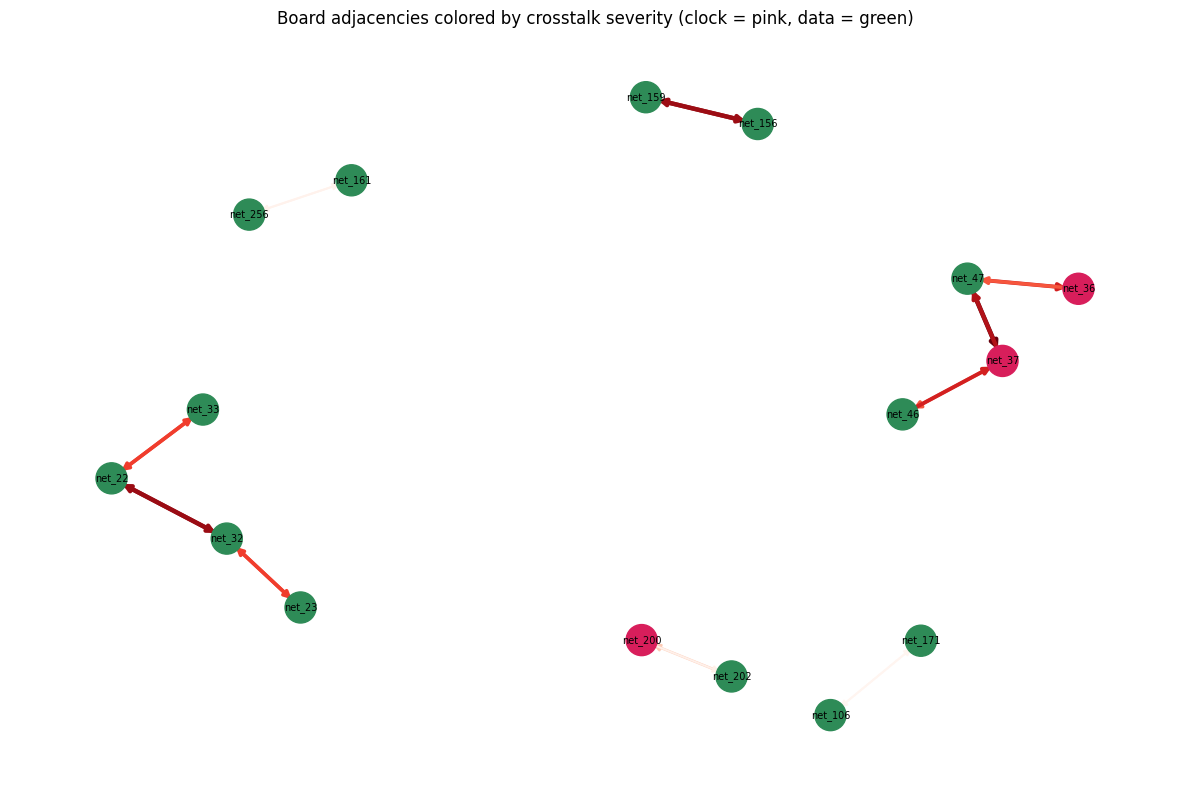

In [12]:
import os
os.makedirs("assets", exist_ok=True)
import matplotlib.pyplot as plt
import networkx as nx

G = nx.DiGraph()
for e in edges:
    v = e["victim_key"]; a = e["aggressor_key"]
    G.add_edge(v, a, severity=e["severity"])

# node color by class
cls = {n["_key"]: n["net_class"] for n in db.aql.execute("FOR n IN nets RETURN {_key:n._key, net_class:n.net_class}")}
palette = {"clock": "#d81e5b", "data": "#2e8b57", "power": "#f5a623", "unknown": "#888"}
node_colors = [palette.get(cls.get(n, "unknown"), "#888") for n in G.nodes()]
edge_sev = [G[u][v]["severity"] for u, v in G.edges()]

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=42, k=0.6)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=500)
nx.draw_networkx_edges(G, pos, edge_color=edge_sev, edge_cmap=plt.cm.Reds,
                       width=[1 + 4*s for s in edge_sev], arrows=True)
nx.draw_networkx_labels(G, pos, font_size=7)
plt.title("Board adjacencies colored by crosstalk severity (clock = pink, data = green)")
plt.savefig("assets/board_severity_map.png", dpi=150, bbox_inches="tight")
plt.axis("off"); plt.tight_layout(); plt.show()

## 12. Net class distribution

A quick sanity check on the classification layer: how the in-scope nets split across data,
clock, and power. The class is read from each net's name and decides how loud it is as an
aggressor in the severity score.

In [13]:
class_counts = list(db.aql.execute("""
  FOR n IN nets
    COLLECT cls = n.net_class WITH COUNT INTO c
    SORT c DESC
    RETURN {class: cls, count: c}
"""))
for r in class_counts:
    print(f"  {r['class']:<8} {r['count']}")

  data     56
  clock    12
  power    5


## 13. Severity ranking — the hero against the field

Every real adjacency, ranked by severity. The bar chart makes the margin visible: the hero
clock-to-data coupling clears the field, and the rest fall away. This is the ranking the judge
sees before it reasons.

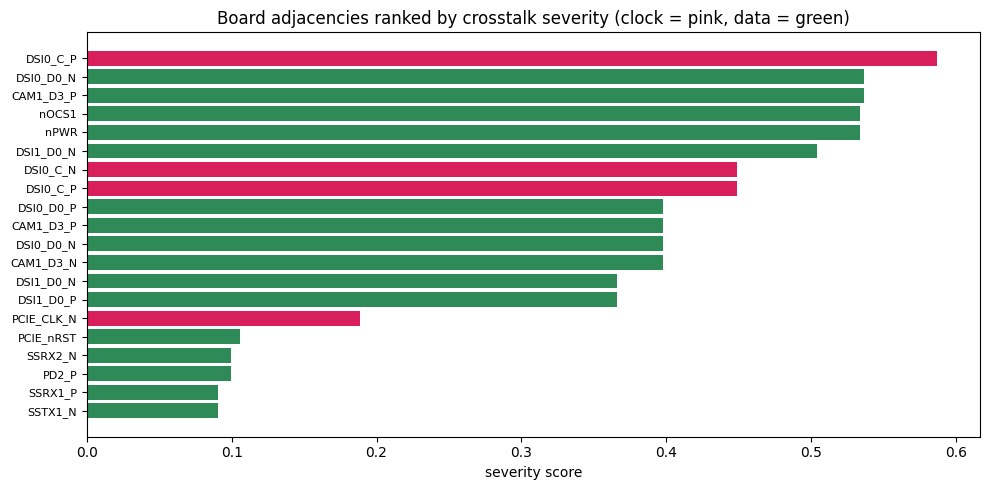

In [14]:
import matplotlib.pyplot as plt

ranked = sorted(edges, key=lambda e: agent.severity(e)[0], reverse=True)
labels = [f"{e['aggressor_name'].split('/')[-1]}" for e in ranked]
scores = [agent.severity(e)[0] for e in ranked]
colors = ["#d81e5b" if e["aggressor_class"]=="clock" else "#2e8b57" for e in ranked]

plt.figure(figsize=(10,5))
plt.barh(range(len(scores)), scores, color=colors)
plt.yticks(range(len(labels)), labels, fontsize=8)
plt.gca().invert_yaxis()
plt.xlabel("severity score")
plt.title("Board adjacencies ranked by crosstalk severity (clock = pink, data = green)")
plt.savefig("assets/severity_ranking.png", dpi=150, bbox_inches="tight")
plt.tight_layout(); plt.show()

## 14. What drives the score — spacing, length, loudness

The severity score is a weighted sum of three normalized terms. Stacking them for the top
adjacencies shows *why* each ranks where it does: the hero wins on length and loudness, not on
spacing, which is exactly the profile a proximity-only check misses.

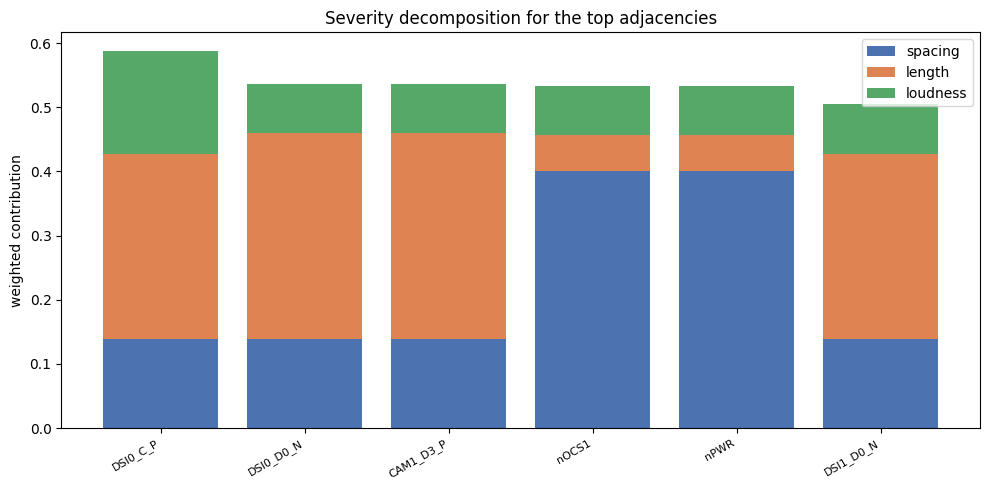

In [15]:
import numpy as np

top = ranked[:6]
names = [e['aggressor_name'].split('/')[-1] for e in top]
parts = [agent.severity(e)[1] for e in top]
spacing = [p['spacing'] for p in parts]
length  = [p['length']  for p in parts]
loud    = [p['loudness'] for p in parts]

x = np.arange(len(names))
plt.figure(figsize=(10,5))
plt.bar(x, spacing, label='spacing', color='#4c72b0')
plt.bar(x, length,  bottom=spacing, label='length', color='#dd8452')
plt.bar(x, loud, bottom=np.array(spacing)+np.array(length), label='loudness', color='#55a868')
plt.xticks(x, names, rotation=30, ha='right', fontsize=8)
plt.ylabel('weighted contribution')
plt.title('Severity decomposition for the top adjacencies')
plt.savefig("assets/severity_decomposition.png", dpi=150, bbox_inches="tight")
plt.legend(); plt.tight_layout(); plt.show()

## 15. The danger region — spacing vs parallel length

Plot every adjacency by its spacing and its parallel run. Crosstalk lives in the lower-right:
close and long. The hero sits there; the healthy neighbors cluster short or far. This is the
two-variable picture the equal spacing/length weighting captures and a single-threshold check
cannot.

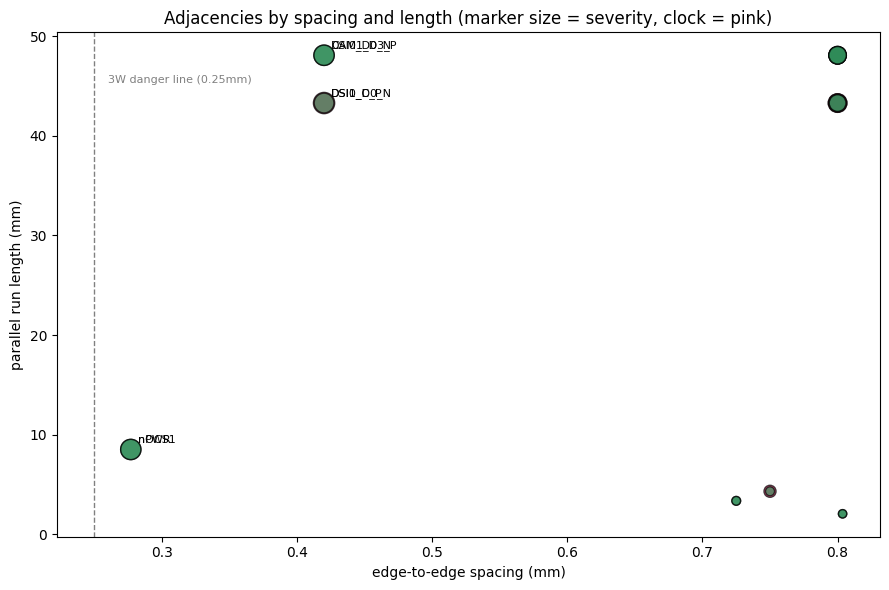

In [16]:
sev = [agent.severity(e)[0] for e in edges]
sp  = [e['spacing_mm'] for e in edges]
ln  = [e['parallel_len_mm'] for e in edges]
cl  = ["#d81e5b" if e['aggressor_class']=='clock' else "#2e8b57" for e in edges]

plt.figure(figsize=(9,6))
plt.scatter(sp, ln, s=[400*s for s in sev], c=cl, alpha=0.7, edgecolors='k')
for e in edges:
    if agent.severity(e)[0] > 0.5:
        plt.annotate(e['aggressor_name'].split('/')[-1], (e['spacing_mm'], e['parallel_len_mm']),
                     fontsize=8, xytext=(5,5), textcoords='offset points')
plt.axvline(0.25, ls='--', c='grey', lw=1)
plt.text(0.26, plt.ylim()[1]*0.9, '3W danger line (0.25mm)', fontsize=8, color='grey')
plt.xlabel('edge-to-edge spacing (mm)'); plt.ylabel('parallel run length (mm)')
plt.title('Adjacencies by spacing and length (marker size = severity, clock = pink)')
plt.savefig("assets/danger_region.png", dpi=150, bbox_inches="tight")
plt.tight_layout(); plt.show()

## What this shows

One Arango deployment resolves a board-defect question end to end. In a single AQL round trip
the marquee query combines graph traversal over the design topology and vector recall over past
defects. The agent then scores each candidate adjacency, judges which one explains the symptom,
and cites the fix through the Retriever.

The result lines up across independent layers. The graph finds a clock running long and close to
a data lane, an adjacency no record-by-record check would surface. The severity score ranks it
above the healthy field. The judge, weighing the recalled cases, picks it over a look-alike
impedance report that shares the symptom. The Retriever, reading only the chosen cause, cites
past reports about the same mechanism. None was told the others' answer, and that agreement is
what a vector-only tool or a single design-rule check cannot produce.

To change the story, edit `config.py` and re-run. To move toward production, point the same
pipeline at your own board, replace the synthetic corpus with real design-review records, and
feed a hardware confirmation back so the finding can reach `confirmed`.